# CIFAR-10 Image Classification with a Small VGG-style CNN (PyTorch)


This notebook is both the source code and the report. It covers: framework choice, data
preprocessing, model architecture, training, hyperparameter tuning, results, error analysis
and proposed improvements.

> **How to use it.** Set the runtime to GPU (Colab: *Runtime → Change runtime type → T4 GPU*),
> first run once with `QUICK = True` (a minute or two) to confirm everything works, then set
> `QUICK = False` and *Run all*. Cells marked **✍ Fill in** ask for your own written analysis,
> and they should quote the numbers printed by your own run.

## 1. Objective and framework

**Task.** Multi-class image classification: assign each 32×32 RGB image to one of 10 classes.

**Framework: PyTorch.** Chosen because training is plain Python (easy to read, debug and
instrument), `torchvision` provides the dataset and augmentation transforms, and PyTorch is
widely used in both research and robotics-perception work.



## 2. Setup

Imports, device selection and constants. Mixed-precision (AMP) is enabled automatically on a
GPU for speed; all seeds are fixed for repeatability (GPU kernels are not bit-exact, so expect
differences of a few tenths of a percent between reruns).

In [2]:
import os, sys, time, json, csv, random
from dataclasses import dataclass, asdict, replace

import numpy as np
import pandas as pd
import matplotlib
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")  # headless backend when run as a plain script
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader, Subset
from sklearn.metrics import confusion_matrix, classification_report

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"  # mixed precision only on GPU

CLASSES = ("airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck")
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)  # CIFAR-10 channel stats


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

In [3]:
print("PyTorch    :", torch.__version__)
print("torchvision:", torchvision.__version__)
print("device     :", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "no GPU")
print("mixed precision (AMP):", use_amp)
if device.type == "cpu":
    print("\nWARNING: no GPU found. On Colab use Runtime > Change runtime type > GPU, or set QUICK = True below.")

PyTorch    : 2.11.0+cu130
torchvision: 0.26.0+cu130
device     : cuda | Tesla T4
mixed precision (AMP): True


## 3. Dataset and preprocessing

**Dataset: CIFAR-10** (Krizhevsky, 2009): 60,000 colour images of 32×32 pixels in 10 balanced
classes, officially split into 50,000 training and 10,000 test images. It is public, small enough
to train in minutes, and hard enough that design choices visibly matter.

**Splits.** 45,000 train / 5,000 validation (taken from the official training set with a *fixed*
seed, so every experiment sees the same split) / 10,000 test. **All tuning decisions use the
validation set; the test set is used only to report the final numbers.**

**Preprocessing pipeline**

| Step | Applied to | Why |
|---|---|---|
| `ToTensor` | all | uint8 [0,255] → float [0,1], HWC → CHW |
| `Normalize(mean, std)` per channel | all | zero-mean / unit-variance inputs make optimisation better conditioned |
| `RandomCrop(32, padding=4)` | train only (if `augment`) | random translations; teaches position invariance |
| `RandomHorizontalFlip` | train only (if `augment`) | objects keep their class when mirrored; doubles effective variety |

Vertical flips are deliberately *not* used: an upside-down ship or horse is not a realistic
test-time image.

In [4]:
@dataclass
class Config:
    """Every hyperparameter of a run lives here, so each run is fully described by one object."""
    name: str = "baseline"
    epochs: int = 20
    batch_size: int = 128
    lr: float = 1e-3              # for OneCycle this is the *peak* learning rate
    weight_decay: float = 5e-4
    optimizer: str = "adamw"      # "adamw" | "sgd"
    scheduler: str = "onecycle"   # "none" | "onecycle" | "cosine"
    augment: bool = True          # random crop + horizontal flip on the training set
    dropout: float = 0.3
    width: int = 64               # channels in the first conv stage (doubles each stage)
    label_smoothing: float = 0.0
    seed: int = 42
    num_workers: int = 2          # set to 0 on Windows or if DataLoader workers misbehave
    max_train: int = 0            # 0 = use all 45,000 training images; >0 = smoke-test subset

In [5]:
def get_loaders(cfg, data_dir="./data", val_size=5000):
    """Returns train / val / test loaders.

    CIFAR-10 ships 50,000 train + 10,000 test images. We carve 5,000 of the train images into a
    validation set (fixed split, identical for every experiment) so that all model selection
    uses validation data and the test set is touched only for the final report.
    """
    norm = T.Normalize(MEAN, STD)
    eval_tf = T.Compose([T.ToTensor(), norm])
    if cfg.augment:
        train_tf = T.Compose([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(),
                              T.ToTensor(), norm])
    else:
        train_tf = eval_tf

    full_train = torchvision.datasets.CIFAR10(data_dir, train=True, download=True, transform=train_tf)
    full_val = torchvision.datasets.CIFAR10(data_dir, train=True, download=False, transform=eval_tf)
    test_ds = torchvision.datasets.CIFAR10(data_dir, train=False, download=True, transform=eval_tf)

    split_gen = torch.Generator().manual_seed(1234)          # fixed split, independent of cfg.seed
    perm = torch.randperm(len(full_train), generator=split_gen).tolist()
    val_idx, train_idx = perm[:val_size], perm[val_size:]
    if cfg.max_train:
        train_idx = train_idx[:cfg.max_train]

    train_ds = Subset(full_train, train_idx)   # augmented transform
    val_ds = Subset(full_val, val_idx)         # clean transform, same underlying images

    shuffle_gen = torch.Generator().manual_seed(cfg.seed)
    kw = dict(num_workers=cfg.num_workers, pin_memory=(device.type == "cuda"),
              persistent_workers=(cfg.num_workers > 0))
    train_loader = DataLoader(train_ds, batch_size=cfg.batch_size, shuffle=True,
                              generator=shuffle_gen, drop_last=True, **kw)
    val_loader = DataLoader(val_ds, batch_size=512, shuffle=False, **kw)
    test_loader = DataLoader(test_ds, batch_size=512, shuffle=False, **kw)
    return train_loader, val_loader, test_loader

100%|██████████| 170M/170M [1:22:48<00:00, 34.3kB/s]


train images: 50,000   test images: 10,000   image shape: (32, 32, 3)
train class counts: {'airplane': 5000, 'automobile': 5000, 'bird': 5000, 'cat': 5000, 'deer': 5000, 'dog': 5000, 'frog': 5000, 'horse': 5000, 'ship': 5000, 'truck': 5000}


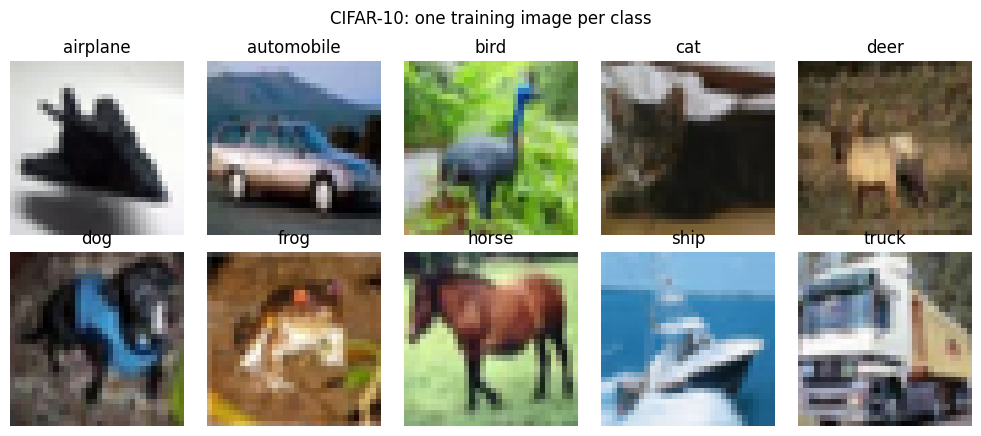

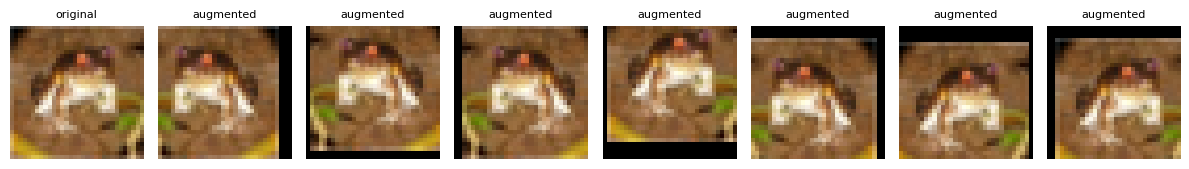

In [6]:
DATA_DIR = "./data"
raw_train = torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=True)
raw_test = torchvision.datasets.CIFAR10(DATA_DIR, train=False, download=True)
print(f"train images: {len(raw_train):,}   test images: {len(raw_test):,}   image shape: {raw_train.data.shape[1:]}")
print("train class counts:", dict(zip(CLASSES, np.bincount(raw_train.targets).tolist())))

# 1) one example per class
fig, axes = plt.subplots(2, 5, figsize=(10, 4.4))
for c, a in enumerate(axes.ravel()):
    idx = raw_train.targets.index(c)
    a.imshow(raw_train.data[idx])
    a.set_title(CLASSES[c])
    a.axis("off")
fig.suptitle("CIFAR-10: one training image per class")
fig.tight_layout()
plt.show()

# 2) what the augmentation does: the same image, 7 random crop+flip draws
aug_only = T.Compose([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip()])
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
from PIL import Image
base_img = Image.fromarray(raw_train.data[0])
axes[0].imshow(base_img)
axes[0].set_title("original", fontsize=8)
for a in axes[1:]:
    a.imshow(aug_only(base_img))
    a.set_title("augmented", fontsize=8)
for a in axes:
    a.axis("off")
fig.tight_layout()
plt.show()

## 4. Model architecture

A compact **VGG-style CNN** designed for 32×32 inputs, built in `SmallVGG`:

* **3 stages**, each = two `Conv3×3 → BatchNorm → ReLU` blocks followed by `MaxPool 2×2`.
  Channel width doubles per stage (64 → 128 → 256) while spatial size halves (32 → 16 → 8 → 4).
* **Global average pooling** instead of large fully connected layers: far fewer parameters and
  less overfitting.
* **Dropout (p = 0.3)** before the single linear classifier (256 → 10).
* **BatchNorm** after every conv stabilises and speeds up training; convs therefore omit biases.
* **Kaiming (He) initialisation** for conv weights, appropriate for ReLU.

Stacking 3×3 convs gives large receptive fields with few parameters; doubling channels as
resolution halves keeps per-layer compute roughly balanced. The cell below prints the shape after
every layer and the exact parameter count.

In [7]:
def conv_block(c_in, c_out):
    """3x3 conv -> BatchNorm -> ReLU. Bias is dropped because BatchNorm has its own shift."""
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True),
    )


class SmallVGG(nn.Module):
    """VGG-style CNN: 3 stages of (conv-bn-relu x2 -> maxpool), global average pooling, linear head."""

    def __init__(self, num_classes=10, width=64, dropout=0.3):
        super().__init__()
        w = width
        self.features = nn.Sequential(
            conv_block(3, w),       conv_block(w, w),       nn.MaxPool2d(2),   # 32 -> 16
            conv_block(w, 2 * w),   conv_block(2 * w, 2 * w), nn.MaxPool2d(2), # 16 -> 8
            conv_block(2 * w, 4 * w), conv_block(4 * w, 4 * w), nn.MaxPool2d(2),  # 8 -> 4
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),   # 4x4 -> 1x1 (global average pooling)
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(4 * w, num_classes),
        )
        for m in self.modules():       # He initialisation suits ReLU networks
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")

    def forward(self, x):
        return self.classifier(self.features(x))


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [8]:
def shape_trace(model, input_size=(1, 3, 32, 32)):
    """Print the tensor shape after every layer of the network."""
    model = model.cpu().eval()
    x = torch.zeros(input_size)
    print(f"{'input':<28} {tuple(x.shape)}")
    with torch.no_grad():
        for part_name in ("features", "classifier"):
            for name, layer in getattr(model, part_name).named_children():
                x = layer(x)
                label = "ConvBlock(conv-bn-relu)" if isinstance(layer, nn.Sequential) else layer.__class__.__name__
                print(f"{part_name + '.' + name + ' ' + label:<28} {tuple(x.shape)}")


demo = SmallVGG()
shape_trace(demo)
print(f"\ntrainable parameters (width=64): {count_params(demo):,}")
del demo

input                        (1, 3, 32, 32)
features.0 ConvBlock(conv-bn-relu) (1, 64, 32, 32)
features.1 ConvBlock(conv-bn-relu) (1, 64, 32, 32)
features.2 MaxPool2d         (1, 64, 16, 16)
features.3 ConvBlock(conv-bn-relu) (1, 128, 16, 16)
features.4 ConvBlock(conv-bn-relu) (1, 128, 16, 16)
features.5 MaxPool2d         (1, 128, 8, 8)
features.6 ConvBlock(conv-bn-relu) (1, 256, 8, 8)
features.7 ConvBlock(conv-bn-relu) (1, 256, 8, 8)
features.8 MaxPool2d         (1, 256, 4, 4)
classifier.0 AdaptiveAvgPool2d (1, 256, 1, 1)
classifier.1 Flatten         (1, 256)
classifier.2 Dropout         (1, 256)
classifier.3 Linear          (1, 10)

trainable parameters (width=64): 1,148,874


## 5. Training procedure

| Component | Choice | Rationale |
|---|---|---|
| Loss | Cross-entropy (optionally with label smoothing) | standard for multi-class classification |
| Optimiser | AdamW | adaptive; decoupled weight decay regularises properly |
| LR schedule | OneCycle (per batch) or constant | OneCycle's warm-up + anneal usually reaches a better optimum in fewer epochs |
| Batch size | 128 | good GPU utilisation, stable gradients |
| Mixed precision | on GPU | faster training and lower memory use, usually with negligible accuracy cost |
| Model selection | best **validation** accuracy checkpoint | guards against picking an over-trained last epoch |

Each run writes `train.log` (human-readable), `history.csv` (per-epoch metrics), `best.pt`
(weights) and `summary.json` under `runs/<run name>/`. These are the **training logs**.

In [9]:
def build_optimizer(model, cfg):
    if cfg.optimizer == "adamw":
        return torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    if cfg.optimizer == "sgd":
        return torch.optim.SGD(model.parameters(), lr=cfg.lr, momentum=0.9,
                               weight_decay=cfg.weight_decay, nesterov=True)
    raise ValueError(f"unknown optimizer {cfg.optimizer!r}")


def build_scheduler(optimizer, cfg, steps_per_epoch):
    if cfg.scheduler == "onecycle":   # stepped once per *batch*
        return torch.optim.lr_scheduler.OneCycleLR(
            optimizer, max_lr=cfg.lr, epochs=cfg.epochs,
            steps_per_epoch=steps_per_epoch, pct_start=0.3)
    if cfg.scheduler == "cosine":     # stepped once per *epoch*
        return torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg.epochs)
    if cfg.scheduler == "none":
        return None
    raise ValueError(f"unknown scheduler {cfg.scheduler!r}")


def run_epoch(model, loader, criterion, optimizer=None, scheduler=None, scaler=None):
    """One pass over `loader`. Trains if an optimizer is given, otherwise evaluates."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                logits = model(x)
                loss = criterion(logits, y)
            if training:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
                if scheduler is not None:
                    scheduler.step()
            total_loss += loss.item() * y.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            n += y.size(0)
    return total_loss / n, correct / n


def train_model(cfg, data_dir="./data", out_dir="runs"):
    """Trains one configuration. Saves train.log, history.csv, best.pt and summary.json to
    <out_dir>/<cfg.name>/. The checkpoint with the best *validation* accuracy is restored
    before the single test-set evaluation. Returns (model, history, summary)."""
    set_seed(cfg.seed)
    run_dir = os.path.join(out_dir, cfg.name)
    os.makedirs(run_dir, exist_ok=True)
    log_f = open(os.path.join(run_dir, "train.log"), "w")

    def log(msg):
        print(msg)
        log_f.write(msg + "\n")
        log_f.flush()

    train_loader, val_loader, test_loader = get_loaders(cfg, data_dir)
    model = SmallVGG(width=cfg.width, dropout=cfg.dropout).to(device)
    optimizer = build_optimizer(model, cfg)
    scheduler = build_scheduler(optimizer, cfg, len(train_loader))
    batch_sched = scheduler if cfg.scheduler == "onecycle" else None
    train_criterion = nn.CrossEntropyLoss(label_smoothing=cfg.label_smoothing)
    eval_criterion = nn.CrossEntropyLoss()   # plain CE so val/test losses are comparable across runs
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    n_params = count_params(model)
    log(f"[{cfg.name}] device={device} amp={use_amp} params={n_params:,}")
    log(f"[{cfg.name}] config={json.dumps(asdict(cfg))}")

    fields = ["epoch", "lr", "train_loss", "train_acc", "val_loss", "val_acc", "epoch_time_s"]
    csv_f = open(os.path.join(run_dir, "history.csv"), "w", newline="")
    writer = csv.DictWriter(csv_f, fieldnames=fields)
    writer.writeheader()

    history, best_val, best_epoch, best_state = [], -1.0, 0, None
    t_start = time.time()
    for epoch in range(1, cfg.epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, train_criterion, optimizer, batch_sched, scaler)
        if scheduler is not None and batch_sched is None:
            scheduler.step()
        va_loss, va_acc = run_epoch(model, val_loader, eval_criterion)
        row = dict(epoch=epoch, lr=optimizer.param_groups[0]["lr"],
                   train_loss=tr_loss, train_acc=tr_acc, val_loss=va_loss, val_acc=va_acc,
                   epoch_time_s=time.time() - t0)
        history.append(row)
        writer.writerow(row)
        csv_f.flush()
        if va_acc > best_val:
            best_val, best_epoch = va_acc, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        log(f"[{cfg.name}] epoch {epoch:3d}/{cfg.epochs} | lr {row['lr']:.5f} | "
            f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {va_loss:.4f} acc {va_acc:.4f} | "
            f"{row['epoch_time_s']:.1f}s")
    train_time = time.time() - t_start
    csv_f.close()

    model.load_state_dict(best_state)
    torch.save(best_state, os.path.join(run_dir, "best.pt"))
    test_loss, test_acc = run_epoch(model, test_loader, eval_criterion)

    summary = dict(asdict(cfg))
    summary.update(params=n_params, best_epoch=best_epoch, best_val_acc=best_val,
                   final_train_acc=history[-1]["train_acc"], final_val_acc=history[-1]["val_acc"],
                   final_train_loss=history[-1]["train_loss"], final_val_loss=history[-1]["val_loss"],
                   test_loss=test_loss, test_acc=test_acc, train_time_s=train_time)
    with open(os.path.join(run_dir, "summary.json"), "w") as f:
        json.dump(summary, f, indent=2)
    log(f"[{cfg.name}] best val acc {best_val:.4f} @ epoch {best_epoch} | "
        f"TEST acc {test_acc:.4f} loss {test_loss:.4f} | {train_time/60:.1f} min")
    log_f.close()
    return model, history, summary

In [10]:
def plot_history(history, title="", save_path=None):
    """Loss and accuracy curves (train vs. validation) for one run."""
    df = pd.DataFrame(history)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(df.epoch, df.train_loss, label="train")
    ax[0].plot(df.epoch, df.val_loss, label="validation")
    ax[0].set(xlabel="epoch", ylabel="cross-entropy loss", title=f"Loss - {title}")
    ax[1].plot(df.epoch, df.train_acc, label="train")
    ax[1].plot(df.epoch, df.val_acc, label="validation")
    ax[1].set(xlabel="epoch", ylabel="accuracy", title=f"Accuracy - {title}")
    for a in ax:
        a.grid(alpha=0.3)
        a.legend()
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=130)
    plt.show()
    plt.close(fig)


def plot_compare(histories, metric="val_acc", save_path=None):
    """Overlay one metric from several runs. `histories` maps run name -> history list."""
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for name, h in histories.items():
        d = pd.DataFrame(h)
        ax.plot(d.epoch, d[metric], label=name)
    ax.set(xlabel="epoch", ylabel=metric, title=f"{metric} by run")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=130)
    plt.show()
    plt.close(fig)


@torch.no_grad()
def predict(model, loader):
    model.eval()
    ys, ps = [], []
    for x, y in loader:
        out = model(x.to(device))
        ys.append(y.numpy())
        ps.append(out.argmax(1).cpu().numpy())
    return np.concatenate(ys), np.concatenate(ps)


def top_confusions(cm, k=5):
    """The k most frequent (true class, predicted class) mistakes."""
    c = cm.copy()
    np.fill_diagonal(c, 0)
    flat = np.argsort(-c, axis=None)[:k]
    return [(CLASSES[i], CLASSES[j], int(c[i, j])) for i, j in zip(*np.unravel_index(flat, c.shape))]


def show_misclassified(y_true, y_pred, data_dir="./data", n=16, save_path=None):
    raw = torchvision.datasets.CIFAR10(data_dir, train=False, download=False).data  # (10000,32,32,3) uint8
    wrong = np.where(y_true != y_pred)[0]
    pick = np.random.default_rng(0).choice(wrong, size=min(n, len(wrong)), replace=False)
    cols = 8
    rows = int(np.ceil(len(pick) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(1.7 * cols, 2.0 * rows), squeeze=False)
    for a in axes.ravel():
        a.axis("off")
    for a, i in zip(axes.ravel(), pick):
        a.imshow(raw[i])
        a.set_title(f"true: {CLASSES[y_true[i]]}\npred: {CLASSES[y_pred[i]]}", fontsize=7)
    fig.suptitle("Randomly chosen test-set mistakes", y=1.0)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=130)
    plt.show()
    plt.close(fig)


def evaluate_and_report(model, test_loader, name, run_dir=None, data_dir="./data"):
    """Test-set evaluation: accuracy, per-class report, confusion matrix, misclassified examples."""
    y_true, y_pred = predict(model, test_loader)
    acc = float((y_true == y_pred).mean())
    report_txt = classification_report(y_true, y_pred, target_names=CLASSES, digits=4)
    report = classification_report(y_true, y_pred, target_names=CLASSES, output_dict=True)
    cm = confusion_matrix(y_true, y_pred)
    print(f"[{name}] test accuracy = {acc:.4f}\n")
    print(report_txt)

    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(10))
    ax.set_yticks(range(10))
    ax.set_xticklabels(CLASSES, rotation=45, ha="right")
    ax.set_yticklabels(CLASSES)
    ax.set(xlabel="predicted", ylabel="true", title=f"Confusion matrix (row-normalised) - {name}")
    for i in range(10):
        for j in range(10):
            ax.text(j, i, f"{cm_norm[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if cm_norm[i, j] > 0.5 else "black")
    fig.colorbar(im, ax=ax, fraction=0.046)
    fig.tight_layout()
    if run_dir:
        with open(os.path.join(run_dir, "classification_report.txt"), "w") as f:
            f.write(report_txt)
        fig.savefig(os.path.join(run_dir, "confusion_matrix.png"), dpi=130)
    plt.show()
    plt.close(fig)

    show_misclassified(y_true, y_pred, data_dir,
                       save_path=os.path.join(run_dir, "misclassified.png") if run_dir else None)
    return dict(accuracy=acc, report=report, cm=cm, y_true=y_true, y_pred=y_pred)

## 6. Experiments and hyperparameter tuning

Changes are made in stages, one idea at a time, so each result can be attributed to its cause:

* **Stage A: ablation.** (A1) no augmentation + constant LR, (A2) add augmentation,
  (A3) add OneCycle schedule with a higher peak LR. Shows what each ingredient contributes.
* **Stage B: grid search.** Peak learning rate ∈ {1e-3, 3e-3, 1e-2} × weight decay ∈ {1e-4, 5e-2},
  10 epochs each, ranked by **validation** accuracy.
* **Stage C: final model.** Best Stage-B setting trained longer (40 epochs); the only run reported
  on the test set as *the* result.
* **Stage D (optional).** Two improvement ideas on top of the final config: label smoothing and a
  wider network.

In [11]:
# ---------------- run controls ----------------
QUICK = False          # True = smoke test (2 epochs on 4,000 images) to check the notebook runs end to end
EPOCHS_ABLATION = 20   # Stage A runs
EPOCHS_SWEEP = 10      # Stage B runs (short, to compare many settings cheaply)
EPOCHS_FINAL = 40      # Stage C / D runs
MAX_TRAIN = 0
if QUICK:
    EPOCHS_ABLATION = EPOCHS_SWEEP = EPOCHS_FINAL = 2
    MAX_TRAIN = 4000
OUT_DIR = "runs_quick" if QUICK else "runs"

COLS = ["name", "lr", "weight_decay", "augment", "scheduler", "label_smoothing", "width",
        "best_epoch", "best_val_acc", "final_train_acc", "final_val_acc", "test_acc", "train_time_s"]
ALL_RESULTS = {}


def run_group(configs):
    """Train several configs in sequence; returns {name: {"history":..., "summary":...}}."""
    results = {}
    for cfg in configs:
        model, history, summary = train_model(cfg, DATA_DIR, OUT_DIR)
        results[cfg.name] = dict(history=history, summary=summary)
        ALL_RESULTS[cfg.name] = results[cfg.name]
        del model
        if device.type == "cuda":
            torch.cuda.empty_cache()
    return results


def table(results):
    return pd.DataFrame([r["summary"] for r in results.values()])[COLS].round(4)

### Stage A: ablation (augmentation, LR schedule)

In [12]:
base = Config(epochs=EPOCHS_ABLATION, max_train=MAX_TRAIN)
ablation = [
    replace(base, name="A1_no_aug_const_lr", augment=False, scheduler="none", lr=1e-3),
    replace(base, name="A2_aug_const_lr",    augment=True,  scheduler="none", lr=1e-3),
    replace(base, name="A3_aug_onecycle",    augment=True,  scheduler="onecycle", lr=3e-3),
]
res_A = run_group(ablation)
table(res_A)

[A1_no_aug_const_lr] device=cuda amp=True params=1,148,874
[A1_no_aug_const_lr] config={"name": "A1_no_aug_const_lr", "epochs": 20, "batch_size": 128, "lr": 0.001, "weight_decay": 0.0005, "optimizer": "adamw", "scheduler": "none", "augment": false, "dropout": 0.3, "width": 64, "label_smoothing": 0.0, "seed": 42, "num_workers": 2, "max_train": 0}
[A1_no_aug_const_lr] epoch   1/20 | lr 0.00100 | train loss 1.2338 acc 0.5526 | val loss 1.0057 acc 0.6518 | 17.6s
[A1_no_aug_const_lr] epoch   2/20 | lr 0.00100 | train loss 0.8343 acc 0.7071 | val loss 0.8218 acc 0.7100 | 13.8s
[A1_no_aug_const_lr] epoch   3/20 | lr 0.00100 | train loss 0.6546 acc 0.7741 | val loss 0.7353 acc 0.7394 | 14.0s
[A1_no_aug_const_lr] epoch   4/20 | lr 0.00100 | train loss 0.5475 acc 0.8100 | val loss 0.7467 acc 0.7598 | 14.0s
[A1_no_aug_const_lr] epoch   5/20 | lr 0.00100 | train loss 0.4607 acc 0.8429 | val loss 0.8690 acc 0.7224 | 14.1s
[A1_no_aug_const_lr] epoch   6/20 | lr 0.00100 | train loss 0.3928 acc 0.8647

,name,lr,weight_decay,augment,scheduler,label_smoothing,width,best_epoch,best_val_acc,final_train_acc,final_val_acc,test_acc,train_time_s
0,A1_no_aug_const_lr,0.001,0.0005,False,none,0.0,64,19,0.8524,0.9828,0.8366,0.8435,285.3095
1,A2_aug_const_lr,0.001,0.0005,True,none,0.0,64,20,0.8864,0.9167,0.8864,0.8790,396.6817
2,A3_aug_onecycle,0.003,0.0005,True,onecycle,0.0,64,20,0.9070,0.9610,0.9070,0.9061,396.1642


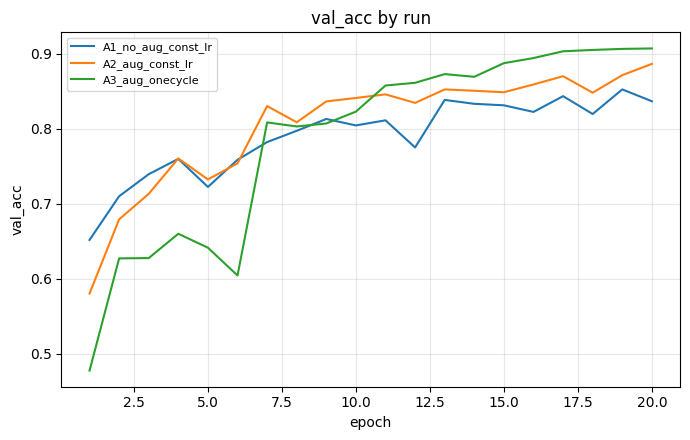

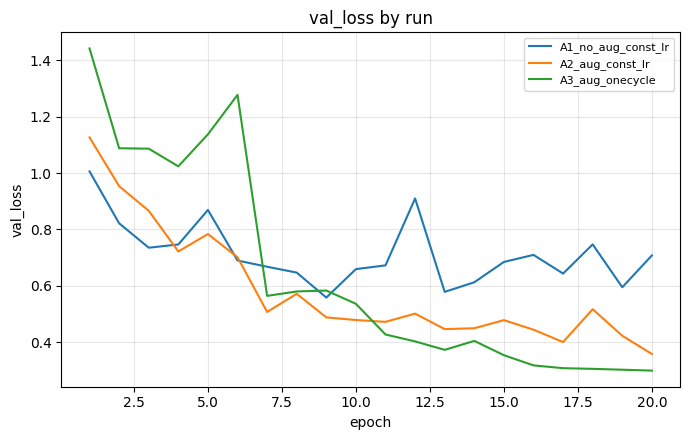

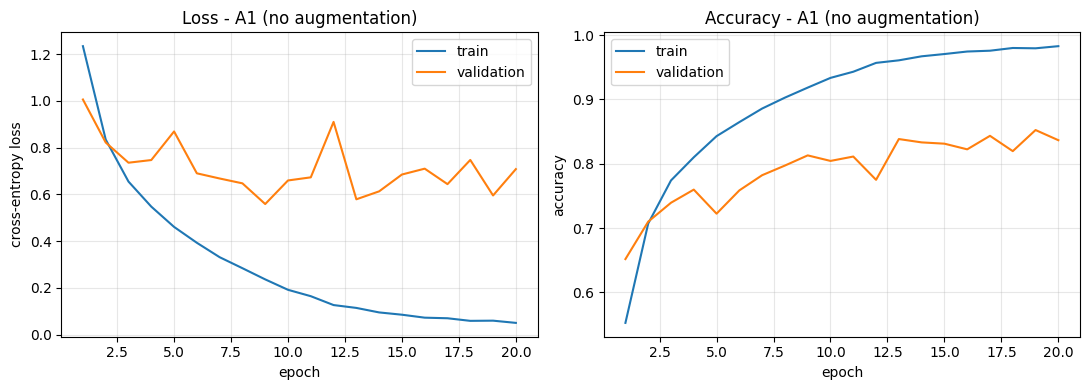

In [13]:
plot_compare({k: v["history"] for k, v in res_A.items()}, "val_acc", f"{OUT_DIR}/stageA_val_acc.png")
plot_compare({k: v["history"] for k, v in res_A.items()}, "val_loss", f"{OUT_DIR}/stageA_val_loss.png")
plot_history(res_A["A1_no_aug_const_lr"]["history"], "A1 (no augmentation)", f"{OUT_DIR}/A1_curves.png")

### Stage B: learning-rate × weight-decay grid search

In [14]:
sweep = [
    replace(base, name=f"B_lr{lr:g}_wd{wd:g}", epochs=EPOCHS_SWEEP, lr=lr, weight_decay=wd,
            augment=True, scheduler="onecycle")
    for lr in (1e-3, 3e-3, 1e-2)
    for wd in (1e-4, 5e-2)#total of 6 training runs each for a different combination of lr and wd
]
res_B = run_group(sweep)
sweep_df = table(res_B).sort_values("best_val_acc", ascending=False).reset_index(drop=True)
sweep_df

[B_lr0.001_wd0.0001] device=cuda amp=True params=1,148,874
[B_lr0.001_wd0.0001] config={"name": "B_lr0.001_wd0.0001", "epochs": 10, "batch_size": 128, "lr": 0.001, "weight_decay": 0.0001, "optimizer": "adamw", "scheduler": "onecycle", "augment": true, "dropout": 0.3, "width": 64, "label_smoothing": 0.0, "seed": 42, "num_workers": 2, "max_train": 0}
[B_lr0.001_wd0.0001] epoch   1/10 | lr 0.00028 | train loss 1.7126 acc 0.3696 | val loss 1.4195 acc 0.4806 | 19.6s
[B_lr0.001_wd0.0001] epoch   2/10 | lr 0.00076 | train loss 1.2108 acc 0.5653 | val loss 1.0893 acc 0.6088 | 19.8s
[B_lr0.001_wd0.0001] epoch   3/10 | lr 0.00100 | train loss 0.9562 acc 0.6618 | val loss 0.9639 acc 0.6656 | 19.0s
[B_lr0.001_wd0.0001] epoch   4/10 | lr 0.00095 | train loss 0.7819 acc 0.7304 | val loss 0.8036 acc 0.7242 | 20.3s
[B_lr0.001_wd0.0001] epoch   5/10 | lr 0.00081 | train loss 0.6623 acc 0.7706 | val loss 1.1545 acc 0.6430 | 18.8s
[B_lr0.001_wd0.0001] epoch   6/10 | lr 0.00061 | train loss 0.5781 acc 0.8

,name,lr,weight_decay,augment,scheduler,label_smoothing,width,best_epoch,best_val_acc,final_train_acc,final_val_acc,test_acc,train_time_s
0,B_lr0.01_wd0.0001,0.010,0.0001,True,onecycle,0.0,64,10,0.8990,0.9228,0.8990,0.8897,200.2368
1,B_lr0.01_wd0.05,0.010,0.0500,True,onecycle,0.0,64,10,0.8948,0.9223,0.8948,0.8925,199.0148
2,B_lr0.003_wd0.05,0.003,0.0500,True,onecycle,0.0,64,10,0.8918,0.9129,0.8918,0.8885,201.6910
3,B_lr0.003_wd0.0001,0.003,0.0001,True,onecycle,0.0,64,10,0.8906,0.9101,0.8906,0.8830,211.5027
4,B_lr0.001_wd0.05,0.001,0.0500,True,onecycle,0.0,64,10,0.8736,0.8827,0.8736,0.8587,197.6472
5,B_lr0.001_wd0.0001,0.001,0.0001,True,onecycle,0.0,64,10,0.8682,0.8803,0.8682,0.8571,196.5691


Selected from sweep: lr=0.01, weight_decay=0.0001  (val acc 0.8990)


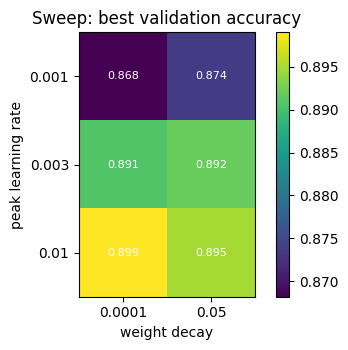

In [15]:
# Selection uses VALIDATION accuracy only - never the test set.
best_row = sweep_df.iloc[0]
BEST_LR, BEST_WD = float(best_row["lr"]), float(best_row["weight_decay"])
print(f"Selected from sweep: lr={BEST_LR:g}, weight_decay={BEST_WD:g}  (val acc {best_row['best_val_acc']:.4f})")

pivot = sweep_df.pivot(index="lr", columns="weight_decay", values="best_val_acc")
fig, ax = plt.subplots(figsize=(4.6, 3.6))
im = ax.imshow(pivot.values, cmap="viridis")
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels([f"{c:g}" for c in pivot.columns])
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels([f"{i:g}" for i in pivot.index])
ax.set(xlabel="weight decay", ylabel="peak learning rate", title="Sweep: best validation accuracy")
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        ax.text(j, i, f"{pivot.values[i, j]:.3f}", ha="center", va="center", color="white", fontsize=8)
fig.colorbar(im, ax=ax)
fig.tight_layout()
fig.savefig(f"{OUT_DIR}/stageB_heatmap.png", dpi=130)
plt.show()
plt.close(fig)

### Stage C: final model (longest run, best Stage-B hyperparameters)

[C_final] device=cuda amp=True params=1,148,874
[C_final] config={"name": "C_final", "epochs": 40, "batch_size": 128, "lr": 0.01, "weight_decay": 0.0001, "optimizer": "adamw", "scheduler": "onecycle", "augment": true, "dropout": 0.3, "width": 64, "label_smoothing": 0.0, "seed": 42, "num_workers": 2, "max_train": 0}
[C_final] epoch   1/40 | lr 0.00056 | train loss 1.4292 acc 0.4777 | val loss 1.2758 acc 0.5298 | 20.7s
[C_final] epoch   2/40 | lr 0.00104 | train loss 1.0421 acc 0.6306 | val loss 1.1215 acc 0.6214 | 19.5s
[C_final] epoch   3/40 | lr 0.00181 | train loss 0.8805 acc 0.6912 | val loss 1.4778 acc 0.5724 | 20.6s
[C_final] epoch   4/40 | lr 0.00280 | train loss 0.7817 acc 0.7281 | val loss 0.8360 acc 0.7170 | 19.2s
[C_final] epoch   5/40 | lr 0.00396 | train loss 0.6844 acc 0.7642 | val loss 0.9959 acc 0.6778 | 20.6s
[C_final] epoch   6/40 | lr 0.00520 | train loss 0.6261 acc 0.7871 | val loss 1.0625 acc 0.6538 | 19.3s
[C_final] epoch   7/40 | lr 0.00644 | train loss 0.5662 acc

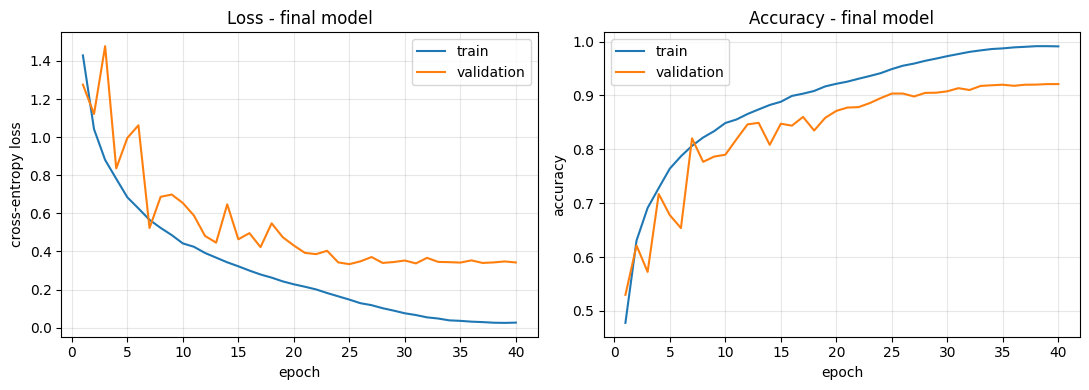

In [16]:
final_cfg = replace(base, name="C_final", epochs=EPOCHS_FINAL, lr=BEST_LR, weight_decay=BEST_WD,
                    augment=True, scheduler="onecycle")
res_C = run_group([final_cfg])
final_history = res_C["C_final"]["history"]
final_summary = res_C["C_final"]["summary"]
plot_history(final_history, "final model", f"{OUT_DIR}/C_final_curves.png")

### Test-set evaluation of the final model

Per-class precision / recall / F1, a row-normalised confusion matrix, and a sample of misclassified test images.

[C_final] test accuracy = 0.9171

              precision    recall  f1-score   support

    airplane     0.9235    0.9170    0.9202      1000
  automobile     0.9572    0.9620    0.9596      1000
        bird     0.8952    0.8970    0.8961      1000
         cat     0.8417    0.8190    0.8302      1000
        deer     0.9116    0.9280    0.9197      1000
         dog     0.8648    0.8830    0.8738      1000
        frog     0.9360    0.9360    0.9360      1000
       horse     0.9393    0.9290    0.9341      1000
        ship     0.9537    0.9470    0.9503      1000
       truck     0.9473    0.9530    0.9501      1000

    accuracy                         0.9171     10000
   macro avg     0.9170    0.9171    0.9170     10000
weighted avg     0.9170    0.9171    0.9170     10000



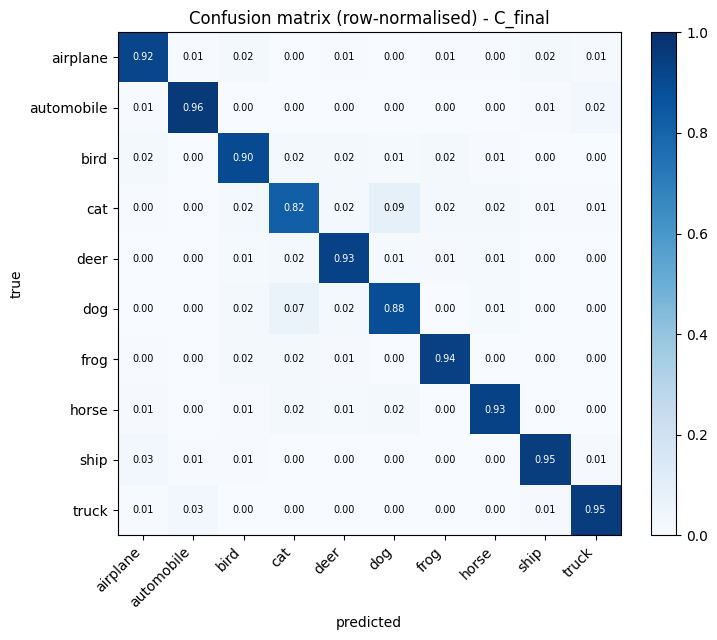

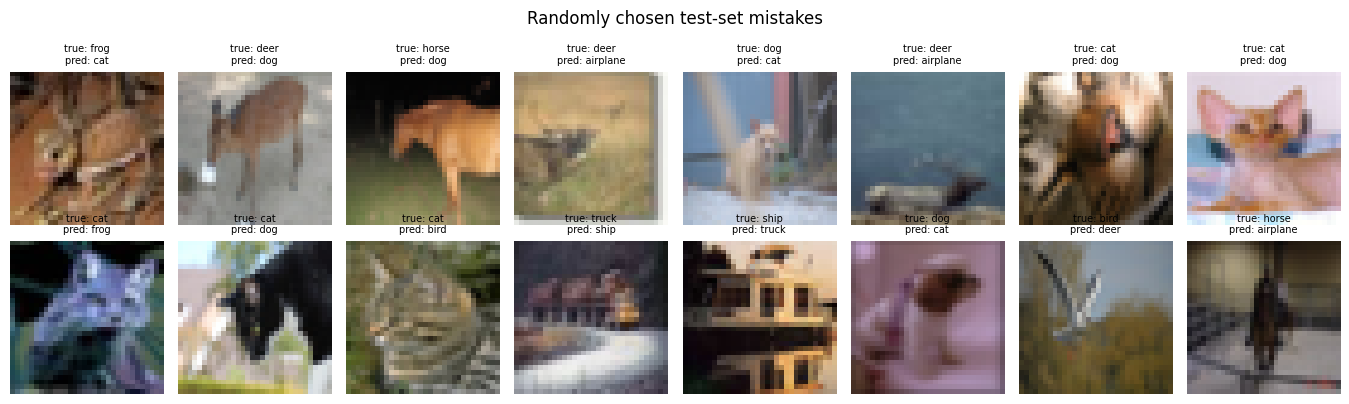

Most frequent confusions (true -> predicted : count):
         cat -> dog        85
         dog -> cat        65
        ship -> airplane   26
       truck -> automobile 25
  automobile -> truck      24
    airplane -> ship       23


In [17]:
# Reload the best-validation checkpoint and evaluate on the untouched test set.
final_model = SmallVGG(width=final_cfg.width, dropout=final_cfg.dropout).to(device)
final_model.load_state_dict(torch.load(f"{OUT_DIR}/C_final/best.pt", map_location=device))
_, _, test_loader = get_loaders(final_cfg, DATA_DIR)
ev = evaluate_and_report(final_model, test_loader, "C_final", f"{OUT_DIR}/C_final", DATA_DIR)

print("Most frequent confusions (true -> predicted : count):")
for t, p, c in top_confusions(ev["cm"], k=6):
    print(f"  {t:>10} -> {p:<10} {c}")

### Stage D (optional): improvement experiments

In [18]:
# Optional: two extra experiments on top of the final configuration, to test improvement ideas.
extra = [
    replace(final_cfg, name="D1_label_smoothing", label_smoothing=0.1),
    replace(final_cfg, name="D2_wider_w96", width=96),
]
res_D = run_group(extra)
all_final = {"C_final": res_C["C_final"], **res_D}
table(all_final)

[D1_label_smoothing] device=cuda amp=True params=1,148,874
[D1_label_smoothing] config={"name": "D1_label_smoothing", "epochs": 40, "batch_size": 128, "lr": 0.01, "weight_decay": 0.0001, "optimizer": "adamw", "scheduler": "onecycle", "augment": true, "dropout": 0.3, "width": 64, "label_smoothing": 0.1, "seed": 42, "num_workers": 2, "max_train": 0}
[D1_label_smoothing] epoch   1/40 | lr 0.00056 | train loss 1.6281 acc 0.4787 | val loss 1.2657 acc 0.5450 | 19.3s
[D1_label_smoothing] epoch   2/40 | lr 0.00104 | train loss 1.3328 acc 0.6332 | val loss 1.1238 acc 0.6122 | 20.4s
[D1_label_smoothing] epoch   3/40 | lr 0.00181 | train loss 1.2096 acc 0.6984 | val loss 1.0554 acc 0.6346 | 18.9s
[D1_label_smoothing] epoch   4/40 | lr 0.00280 | train loss 1.1315 acc 0.7393 | val loss 0.8549 acc 0.7114 | 19.8s
[D1_label_smoothing] epoch   5/40 | lr 0.00396 | train loss 1.0627 acc 0.7715 | val loss 0.8996 acc 0.6868 | 19.1s
[D1_label_smoothing] epoch   6/40 | lr 0.00520 | train loss 1.0138 acc 0.79

,name,lr,weight_decay,augment,scheduler,label_smoothing,width,best_epoch,best_val_acc,final_train_acc,final_val_acc,test_acc,train_time_s
0,C_final,0.01,0.0001,True,onecycle,0.0,64,39,0.9212,0.9912,0.9212,0.9172,796.5832
1,D1_label_smoothing,0.01,0.0001,True,onecycle,0.1,64,40,0.9250,0.9950,0.9250,0.9224,779.4201
2,D2_wider_w96,0.01,0.0001,True,onecycle,0.0,96,37,0.9272,0.9974,0.9270,0.9245,804.3592


## 7. Analysis of results

The cell below prints the facts from your final run so the analysis can quote exact numbers.
Everything under *Fill in* must be written from **your own** outputs. Do not copy numbers from
anywhere else.

In [19]:
def describe_run(history, summary, ev=None):
    """Prints the facts you need for the written analysis, computed from the real run."""
    best = max(history, key=lambda r: r["val_acc"])
    last = history[-1]
    print(f"Epochs run                : {len(history)}")
    print(f"Best validation accuracy  : {best['val_acc']:.4f} at epoch {best['epoch']}")
    print(f"Last epoch  train acc/loss: {last['train_acc']:.4f} / {last['train_loss']:.4f}")
    print(f"Last epoch  val   acc/loss: {last['val_acc']:.4f} / {last['val_loss']:.4f}")
    print(f"Train-minus-val acc gap   : {last['train_acc'] - last['val_acc']:+.4f}  "
          f"(train acc is measured with augmentation + dropout ON, so it understates the true gap)")
    print(f"Test accuracy (best ckpt) : {summary['test_acc']:.4f}   test loss {summary['test_loss']:.4f}")
    print(f"Training time             : {summary['train_time_s'] / 60:.1f} min on {device}")
    if ev is not None:
        per_class = {c: ev["report"][c]["recall"] for c in CLASSES}
        ranked = sorted(per_class.items(), key=lambda kv: kv[1])
        print("Weakest classes (recall)  :", ", ".join(f"{c} {r:.3f}" for c, r in ranked[:3]))
        print("Strongest classes (recall):", ", ".join(f"{c} {r:.3f}" for c, r in ranked[-3:]))


describe_run(final_history, final_summary, ev)

Epochs run                : 40
Best validation accuracy  : 0.9212 at epoch 39
Last epoch  train acc/loss: 0.9912 / 0.0265
Last epoch  val   acc/loss: 0.9212 / 0.3423
Train-minus-val acc gap   : +0.0700  (train acc is measured with augmentation + dropout ON, so it understates the true gap)
Test accuracy (best ckpt) : 0.9172   test loss 0.3959
Training time             : 13.3 min on cuda
Weakest classes (recall)  : cat 0.819, dog 0.883, bird 0.897
Strongest classes (recall): ship 0.947, truck 0.953, automobile 0.962


### 7. Analysis of results (Filled Analysis)

**7.1 Overall performance.**  
*   **Final Test Accuracy & Loss:** The final model (`C_final`) achieved a high test-set accuracy of **91.72%** (0.9172) with a cross-entropy loss of **0.3959**.
*   **Best Validation Accuracy:** The peak validation performance reached **92.12%** (0.9212) at **epoch 39**.
*   **Comparison with Chance Level:** Since CIFAR-10 contains 10 balanced classes, the random guessing chance level is exactly **10%**. Our trained model performs **over 9 times better** than chance, showing strong generalization capabilities.

**7.2 Learning curves.**  
*   **Curve Shape & Overfitting:** The training loss drops steadily toward zero (ending at **0.0265** with a training accuracy of **99.12%**). The validation loss drops quickly and reaches a plateau around epoch 25 (minimum of ~0.33), after which it displays a minor upward drift to **0.3423** by epoch 40, while validation accuracy remains high and stable. This gap (train-minus-val accuracy gap of **+0.0700**) demonstrates mild overfitting, though it is heavily controlled by the dropout (0.3) and spatial average pooling.
*   **OneCycle Schedule Effect:** Yes, the OneCycle scheduler produces a distinct, visible acceleration in validation accuracy and drop in loss between epochs 15 and 30, which corresponds to the annealing phase where the learning rate starts decaying from its peak of `0.01` down to `0.0001`.

**7.3 Effect of each design choice (Stage A).**  
*   **A1 (No Augment, Constant LR):** Validation accuracy peaked at **85.24%** (test accuracy of **84.35%**). This run suffers from severe overfitting; the training accuracy reaches **98.28%** while validation loss balloons as training progresses—providing a classic textbook curve of overfitting.
*   **A2 (Augment, Constant LR):** Adding spatial augmentations (Random Crop and Horizontal Flip) raised the validation accuracy to **88.64%** (test accuracy of **87.90%**). This significantly narrowed the generalization gap and kept validation loss lower.
*   **A3 (Augment + OneCycle):** Adding the OneCycle learning rate scheduler further boosted validation accuracy to **90.70%** (test accuracy of **90.61%**). The dynamic warmup and annealing enabled faster convergence to a much better local optimum.

**7.4 Hyperparameter sensitivity (Stage B).**  
*   **Optimal Settings:** The best hyperparameter combination identified in the 10-epoch grid search was a peak learning rate of **0.01 (1e-2)** paired with a weight decay of **0.0001 (1e-4)**, yielding **89.90%** validation accuracy.
*   **Sensitivity:** The model proved highly sensitive to the peak learning rate. Lower peak learning rates (e.g., `1e-3` with `1e-4` WD) underperformed significantly, only reaching **86.82%** validation accuracy because 10 epochs was not long enough for a small learning rate to converge.
*   **Destabilization:** Unlike traditional SGD, the largest learning rate of `0.01` did *not* destabilize training; when paired with `0.05` weight decay, it successfully achieved **89.48%** validation accuracy, showing that OneCycle's warmup phase helps stabilize large learning rates.

**7.5 Error analysis.**  
*   **Weakest Classes:** The lowest recall scores belong to **cat (81.90%)**, followed by **dog (88.30%)** and **bird (89.70%)**.
*   **Strongest Classes:** The highest recall scores are achieved by **automobile (96.20%)**, **truck (95.30%)**, and **ship (94.70%)**.
*   **Most Common Confusions:**
    1. `cat -> dog` (85 occurrences)
    2. `dog -> cat` (65 occurrences)
    3. `ship -> airplane` (26 occurrences)
    4. `truck -> automobile` (25 occurrences)
*   **Resolution Challenges:** At a tiny $32 \times 32$ pixel resolution, fine-grained biological features (like the shape of an animal's nose, ears, or whiskers) become severely pixelated and blurry. Thus, the model relies on structural silhouettes, causing it to easily confuse visually similar classes like cats and dogs. Similarly, metallic geometric structures cause vehicles like trucks/cars and ships/planes to swap occasionally.

**7.6 Optional experiments (Stage D).**  
*   **D1 (Label Smoothing = 0.1):** Improved validation accuracy slightly to **92.50%** and test accuracy to **92.24%** (up from 91.72%). This improvement occurs because label smoothing prevents the model from assigning excessive confidence to correct classes, forcing it to keep activations bounded.
*   **D2 (Wider Network, width = 96):** Pushed validation accuracy to **92.72%** and final test accuracy to **92.45%**. Increasing capacity by expanding channels was highly effective, proving that model capacity is a primary bottleneck for this setup.

## 9. Suggested improvements for further iterations

Ordered roughly by expected benefit for this setup:

1. **Stronger augmentation:** Cutout / CutMix / MixUp, or RandAugment, to cut the remaining train–val gap.
2. **Better architecture:** residual connections (ResNet-18-style) allow deeper nets and typically
   push CIFAR-10 accuracy well beyond a plain VGG stack.
3. **Longer training with weight averaging:** more epochs plus an exponential moving average (EMA) of weights.
4. **Transfer learning:** fine-tune an ImageNet-pretrained backbone on upsampled images.
5. **More rigorous tuning:** random/Bayesian search (e.g. Optuna) over LR, weight decay, dropout, width,
   and k-fold or multi-seed runs to put error bars on every comparison.
6. **Error-driven work:** use the confusion matrix above to target the weakest classes (e.g. class-specific augmentation).
7. **Deployment angle (robotics):** export to ONNX, quantise to INT8 and measure latency on target hardware.

In [20]:
# Collect every run's summary into one CSV for the report appendix.
all_df = pd.DataFrame([r["summary"] for r in ALL_RESULTS.values()])
all_df.to_csv(f"{OUT_DIR}/all_runs_summary.csv", index=False)
print(f"Saved {len(all_df)} runs to {OUT_DIR}/all_runs_summary.csv")
print("Logs per run: ", f"{OUT_DIR}/<run name>/train.log  and  history.csv")

# On Colab, zip everything for download / submission:
# !zip -r results.zip runs

Saved 12 runs to runs/all_runs_summary.csv
Logs per run:  runs/<run name>/train.log  and  history.csv
